# Notebook 8. Cierre


Objetivo: comparar V0 a V7 en calidad, latencia y coste con la tabla acumulativa y decidir qué versión usarías.

Referencias:
- RAG original: https://arxiv.org/abs/2005.11401
- Survey de RAG: https://arxiv.org/abs/2312.10997

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada


Trazas:      jsonl /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/trazas/trazas.jsonl  (alumno: profesor)


/home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/rag_lab/tracing.py:49: UserWarning: No se pudo conectar con Langfuse ([Errno 111] Connection refused): las trazas se guardan en JSONL.
  warnings.warn(f"No se pudo conectar con Langfuse ({e}): las trazas se guardan en JSONL.")


In [2]:
from rag_lab import results

table = results.table("pdf")
table[["notebook", "tecnica", "recall@5", "recall@10", "MRR@10", "recall@5_texto", "recall@5_tabla",
       "recall@5_visual", "fidelidad", "relevancia_respuesta", "relevancia_contexto",
       "latencia_p50_ms", "latencia_p95_ms", "tokens", "coste_usd"]].round(3)

,notebook,tecnica,recall@5,recall@10,MRR@10,recall@5_texto,recall@5_tabla,recall@5_visual,fidelidad,relevancia_respuesta,relevancia_contexto,latencia_p50_ms,latencia_p95_ms,tokens,coste_usd
version,,,,,,,,,,,,,,,
V0,3,Chunking fijo (800/100) + denso BGE-M3,0.9,1.0,0.780,1.0,1.0,0.667,0.7,1.0,0.70,750.405,1381.430,19402.0,0.005
V1,3,Chunking por cabeceras y tablas completas + de...,1.0,1.0,0.808,1.0,1.0,1.000,0.8,1.0,0.80,738.650,1271.994,33019.0,0.009
V2,4,"BM25 (bm25s, stemmer y stopwords en español)",0.9,0.9,0.760,1.0,1.0,0.667,0.8,1.0,0.80,654.015,1199.411,32168.0,0.009
V3,4,Híbrido BM25 + denso con RRF,1.0,1.0,0.858,1.0,1.0,1.000,0.8,1.0,0.80,637.565,815.302,33853.0,0.009
V4,5,V3 + reranker bge-reranker-v2-m3 (top-50),0.9,0.9,0.798,1.0,1.0,0.667,0.8,1.0,0.80,1907.240,2482.916,34403.0,0.009
V5,5,"V4 + metadatos (ruta de sección, cabecera de c...",0.9,0.9,0.838,1.0,1.0,0.667,0.8,1.0,0.80,2366.005,3253.320,60631.0,0.016
V6,5,"V5 + multi-query (3 reformulaciones, RRF)",0.9,0.9,0.838,1.0,1.0,0.667,0.8,1.0,0.80,3137.915,3951.608,64087.0,0.019
V7,7,V6 + unidades visuales (descripción VLM + SIGL...,1.0,1.0,0.935,1.0,1.0,1.000,0.9,1.0,0.85,3490.145,4751.862,76031.0,0.022


Todas las cifras salen de `results.csv`, que escriben los notebooks 3 a 7. El coste es el de las 20 preguntas
(en USD, la unidad que devuelve OpenRouter) y no incluye el judge. Con 20 preguntas, una pregunta son 5 puntos de
recall global: no leas diferencias pequeñas como mejoras reales.

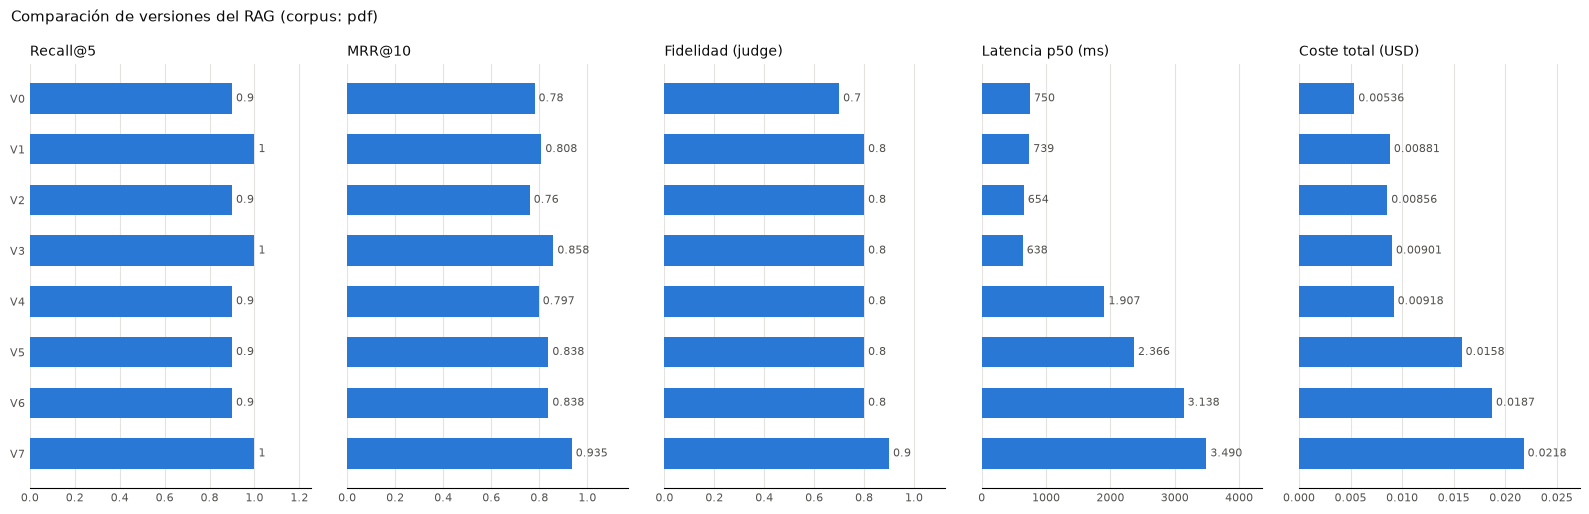

In [3]:
chart = results.plot_comparison("pdf", path=CFG.RESULTS_CSV.parent / "resultados_final.png")

In [4]:
# Calidad frente a coste por pregunta: ¿cuánto pagas por cada punto de calidad?
summary = table[["recall@5", "MRR@10", "fidelidad", "latencia_p50_ms", "coste_usd"]].copy()
summary["coste_por_pregunta_usd"] = summary["coste_usd"] / 20
summary["MRR@10 por céntimo"] = summary["MRR@10"] / (summary["coste_por_pregunta_usd"] * 100)
summary.round(4)

,recall@5,MRR@10,fidelidad,latencia_p50_ms,coste_usd,coste_por_pregunta_usd,MRR@10 por céntimo
version,,,,,,,
V0,0.9,0.7801,0.7,750.405,0.0054,0.0003,29.1040
V1,1.0,0.8083,0.8,738.650,0.0088,0.0004,18.3431
V2,0.9,0.7600,0.8,654.015,0.0086,0.0004,17.7632
V3,1.0,0.8583,0.8,637.565,0.0090,0.0005,19.0460
V4,0.9,0.7975,0.8,1907.240,0.0092,0.0005,17.3733
V5,0.9,0.8375,0.8,2366.005,0.0158,0.0008,10.6221
V6,0.9,0.8375,0.8,3137.915,0.0187,0.0009,8.9504
V7,1.0,0.9350,0.9,3490.145,0.0218,0.0011,8.5858


## Elige tu versión

Completa la celda con la versión que pondrías en producción para este documento y justifícala con la tabla:
qué tipo de preguntas te importa más, cuánta latencia aceptas y cuánto puedes pagar por consulta.

In [5]:
chosen_version = ""  # por ejemplo "V3"
max_latency_ms = 0  # la que aceptarías en p95
priority_type = ""  # "texto", "tabla" o "visual"

if chosen_version in table.index:
    row = table.loc[chosen_version]
    print(f"{chosen_version}: {row['tecnica']}")
    print(f"recall@5 {row['recall@5']:.2f} | {priority_type}: {row.get('recall@5_' + priority_type, float('nan')):.2f} | "
          f"p95 {row['latencia_p95_ms']:.0f} ms (máximo {max_latency_ms}) | {row['coste_usd'] / 20:.5f} USD por pregunta")
    cheaper = table[(table["recall@5_" + priority_type] >= row["recall@5_" + priority_type]) &
                        (table["coste_usd"] < row["coste_usd"])].index.tolist() if priority_type else []
    print("Versiones igual de buenas en tu tipo prioritario y más baratas:", cheaper or "ninguna")
else:
    print("Completa chosen_version, max_latency_ms y priority_type.")

Completa chosen_version, max_latency_ms y priority_type.


## Qué hemos visto

- Cada versión resuelve un fallo concreto de la anterior y casi todas añaden latencia o coste.
- La media global oculta diferencias por tipo de pregunta: hay que mirar el desglose.
- La elección depende del uso: tipo de pregunta prioritario, latencia aceptable y presupuesto por consulta.

## Ejercicio propuesto

Propón una V8 que mantenga la calidad de tu versión elegida en tu tipo de pregunta prioritario con menos
latencia, y explica qué paso de las trazas eliminarías o sustituirías.